# Minimum Wage and Youth Unemployment in the EU

**Author:** Abdulhamit Ayaz  
**Course:** Methods and Applications of Machine Learning, 2025–2026

## 1. Research question

How is the minimum-wage-to-median-wage ratio associated with youth unemployment in this EU panel, and how sensitive are estimates to the modelling approach and controls?

The analysis uses 177 country-year observations for 20 countries, 2014–2022. It compares two-way fixed-effects OLS, LASSO and a DoubleML PLR exercise. This is an exploratory course project, not definitive evidence of a policy effect. Python coding was supported by AI assistance; the research question and analytical approach were developed by the author.


In [1]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path('data_final.csv')
df = pd.read_csv(DATA_PATH)
assert not df.duplicated(['country', 'year']).any(), 'Duplicate country-year observations'
assert not df[['country', 'year', 'youth_unemp', 'minwage_ratio', 'gdp_growth', 'total_unemp']].isna().any().any()
print('Data loaded:', df.shape)


Data loaded: (177, 8)


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from doubleml import DoubleMLData, DoubleMLPLR
from sklearn.ensemble import RandomForestRegressor


df = pd.read_csv(DATA_PATH)
print('Data loaded:', df.shape)

Data loaded: (177, 8)


## 2. Data

We use three Eurostat datasets merged into an **almost balanced** country-year panel.
The final dataset contains 177 observations for 20 EU countries over 2014-2022.
The only missing country-year observations are Germany 2014 and Ireland 2021-2022.

| Variable | Source | Description |
|---|---|---|
| `youth_unemp` | une_rt_a | Youth unemployment rate (15-24 age group, %) |
| `minwage_ratio` | earn_mw_avgr2 | Minimum wage as % of median wage |
| `gdp_growth` | tec00115 | GDP growth rate (%) |
| `total_unemp` | une_rt_a | Overall unemployment rate (20-64 age group, %) |

**Coverage:** 20 EU countries, 2014-2022 (177 observations)  
**Note:** Greece (EL) excluded due to insufficient time coverage (only 2 observations). Countries without statutory minimum wage (AT, CY, DK, FI, IT, SE) are not included in Eurostat minimum wage statistics.

In [3]:
print('=== DATASET OVERVIEW ===')
print(f'Countries: {df["country"].nunique()}')
print(f'Years: {df["year"].min()} - {df["year"].max()}')
print(f'Observations: {len(df)}')
print(f'Missing values: {df.isnull().sum().sum()}')
print('\n=== SUMMARY STATISTICS ===')
print(df[['youth_unemp','minwage_ratio','gdp_growth','total_unemp']].describe().round(2))

=== DATASET OVERVIEW ===
Countries: 20
Years: 2014 - 2022
Observations: 177
Missing values: 0

=== SUMMARY STATISTICS ===
       youth_unemp  minwage_ratio  gdp_growth  total_unemp
count       177.00         177.00      177.00       177.00
mean         17.74          44.35        3.09         6.97
std           8.44           4.39        3.91         3.58
min           5.60          32.80      -10.90         2.00
25%          11.80          41.60        1.80         4.60
50%          16.30          43.70        2.90         6.30
75%          21.00          47.10        4.90         8.10
max          53.20          55.20       24.60        24.10


## 3. Exploratory Data Analysis

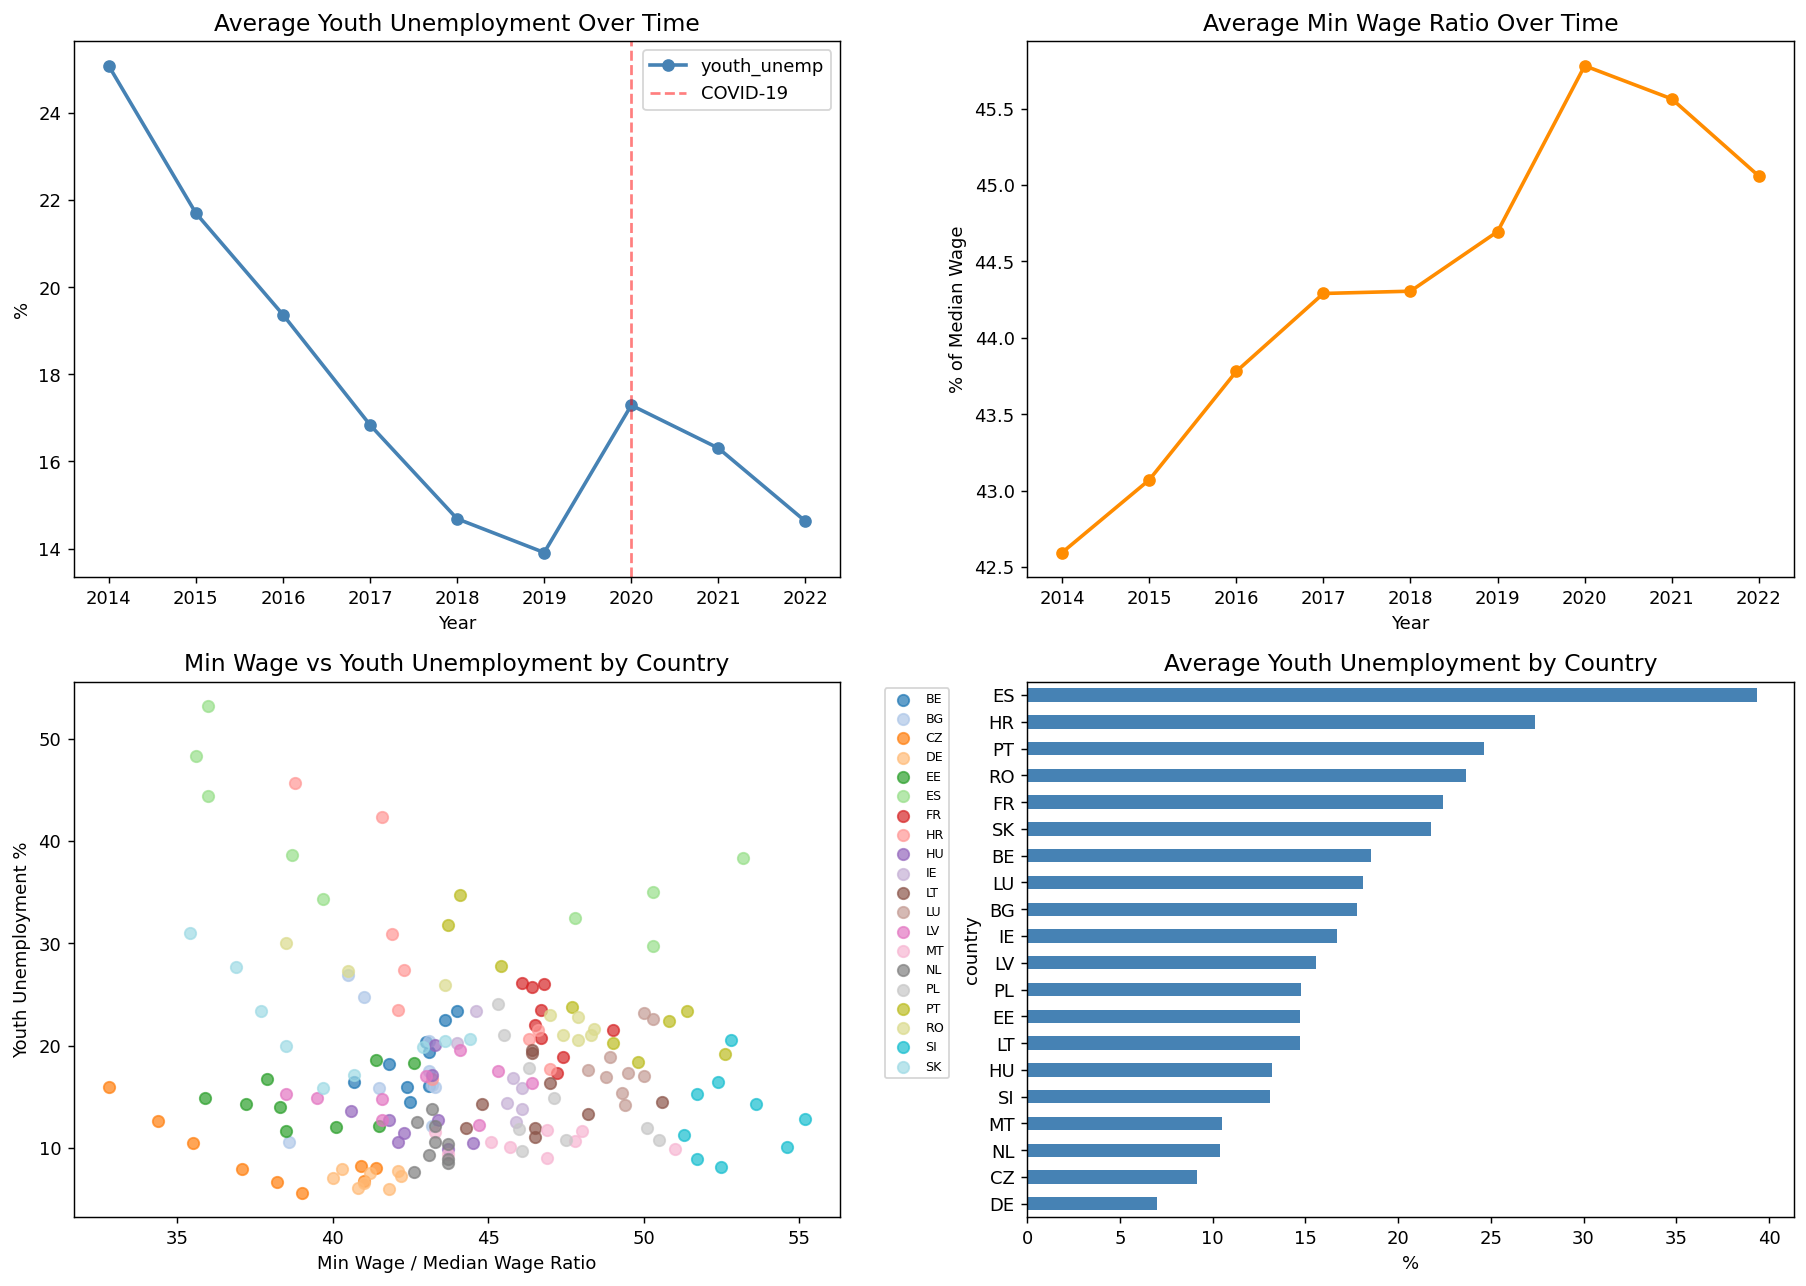

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Youth unemployment over time
df.groupby('year')['youth_unemp'].mean().plot(
    ax=axes[0,0], marker='o', color='steelblue', linewidth=2)
axes[0,0].set_title('Average Youth Unemployment Over Time', fontsize=13)
axes[0,0].set_ylabel('%')
axes[0,0].set_xlabel('Year')
axes[0,0].axvline(x=2020, color='red', linestyle='--', alpha=0.5, label='COVID-19')
axes[0,0].legend()

# 2. Min wage ratio over time
df.groupby('year')['minwage_ratio'].mean().plot(
    ax=axes[0,1], marker='o', color='darkorange', linewidth=2)
axes[0,1].set_title('Average Min Wage Ratio Over Time', fontsize=13)
axes[0,1].set_ylabel('% of Median Wage')
axes[0,1].set_xlabel('Year')

# 3. Scatter by country
colors = plt.cm.tab20(np.linspace(0, 1, df['country'].nunique()))
for i, country in enumerate(sorted(df['country'].unique())):
    subset = df[df['country'] == country]
    axes[1,0].scatter(subset['minwage_ratio'], subset['youth_unemp'],
                      label=country, color=colors[i], alpha=0.7, s=40)
axes[1,0].set_xlabel('Min Wage / Median Wage Ratio')
axes[1,0].set_ylabel('Youth Unemployment %')
axes[1,0].set_title('Min Wage vs Youth Unemployment by Country', fontsize=13)
axes[1,0].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7)

# 4. Bar chart by country
df.groupby('country')['youth_unemp'].mean().sort_values(ascending=True).plot(
    kind='barh', ax=axes[1,1], color='steelblue')
axes[1,1].set_title('Average Youth Unemployment by Country', fontsize=13)
axes[1,1].set_xlabel('%')

plt.tight_layout()
plt.show()

### Key Observations

- **Youth unemployment declined steadily** from ~25% in 2014 to ~14% in 2019, reflecting the post-financial-crisis recovery across EU countries.
- **COVID-19 (2020)** caused a visible spike in youth unemployment, confirming that year fixed effects are important to control for common shocks.
- **Minimum wage ratio increased** over the same period, suggesting a potential negative relationship — but this is descriptive, not causal.
- **Spain (ES)** shows the highest youth unemployment throughout the period, while **Czech Republic (CZ)** and **Germany (DE)** show the lowest.
- The within-country variation in minimum wage ratio over time is the key source of identification in the panel analysis.

---

## 4. Identification Strategy

We exploit **within-country variation** in minimum wage ratios over time to estimate the conditional relationship on youth unemployment.

**Model:**

$$Y_{it} = \beta \cdot D_{it} + \gamma_1 GDP_{it} + \gamma_2 TotalUnemp_{it} + \alpha_i + \lambda_t + \varepsilon_{it}$$

Where:
- $Y_{it}$ = youth unemployment rate in country $i$, year $t$
- $D_{it}$ = minimum wage / median wage ratio (treatment)
- $\alpha_i$ = country fixed effects (absorb time-invariant differences)
- $\lambda_t$ = year fixed effects (absorb common shocks like COVID-19)

Standard errors are clustered at the country level to allow for serial correlation within countries.

**Key assumption:** Conditional on fixed effects and controls, changes in minimum wage ratio are uncorrelated with unobserved shocks to youth unemployment.

## 5. Statistical modelling

1. **Two-way fixed-effects OLS:** baseline conditional association with country-clustered standard errors.
2. **LASSO:** regularized regression; standardized coefficients are not directly comparable with OLS, and no significance tests are reported.
3. **DoubleML PLR:** exploratory comparison using random forests and ordinary five-fold cross-fitting. Country/year dummies enter as predictors; this is not equivalent to the within transformation. This implementation does not use cluster-aware sample splitting or country-clustered inference, so its reported uncertainty must be treated cautiously.


In [5]:
# ============================================
# MODEL 1: OLS TWO-WAY FIXED EFFECTS
# ============================================
country_dummies = pd.get_dummies(df['country'], drop_first=True, prefix='c')
year_dummies = pd.get_dummies(df['year'], drop_first=True, prefix='y')

X_ols = pd.concat([
    df[['minwage_ratio','gdp_growth','total_unemp']],
    country_dummies,
    year_dummies
], axis=1)

X_ols = sm.add_constant(X_ols)
y_ols = df['youth_unemp']

ols_model = sm.OLS(y_ols, X_ols.astype(float)).fit(
    cov_type='cluster',
    cov_kwds={'groups': df['country']}
)

print('=== MODEL 1: OLS TWO-WAY FIXED EFFECTS ===')
print(f'Coefficient (minwage_ratio): {ols_model.params["minwage_ratio"]:.4f}')
print(f'Std Error (clustered):       {ols_model.bse["minwage_ratio"]:.4f}')
print(f'P-value:                     {ols_model.pvalues["minwage_ratio"]:.4f}')
print(f'95% CI: [{ols_model.conf_int().loc["minwage_ratio",0]:.4f}, '
      f'{ols_model.conf_int().loc["minwage_ratio",1]:.4f}]')
print(f'R-squared:                   {ols_model.rsquared:.4f}')
print(f'Observations:                {int(ols_model.nobs)}')

=== MODEL 1: OLS TWO-WAY FIXED EFFECTS ===
Coefficient (minwage_ratio): -0.0221
Std Error (clustered):       0.0634
P-value:                     0.7270
95% CI: [-0.1463, 0.1021]
R-squared:                   0.9756
Observations:                177


### Model 1 Results: OLS Two-Way Fixed Effects

| | Value |
|---|---|
| Coefficient | -0.0221 |
| Std Error (clustered by country) | 0.0634 |
| P-value | 0.7270 |
| 95% CI | [-0.146, 0.102] |
| R-squared | 0.9756 |
| Observations | 177 |

*Standard errors clustered at the country level to allow for serial correlation within countries.*

**Interpretation:** A one percentage point increase in the minimum wage ratio is associated with a **0.022 percentage point decrease** in youth unemployment, after controlling for country fixed effects, year fixed effects, GDP growth, and overall unemployment. However, this effect is **not statistically significant** (p = 0.727), and the confidence interval includes both negative and positive values.

The very high R² (0.976) reflects the explanatory power of the full model, including controls and fixed effects; it does not isolate the contribution of the fixed effects or establish causality. The model explains much of the variation in youth unemployment.

=== MODEL 2: LASSO ===
Best alpha (lambda):         0.0077
Non-zero coefficients:       29 / 30
Coefficient (minwage_ratio): -0.0699

Top 10 non-zero coefficients (by absolute value):
total_unemp    7.6011
c_RO           1.4875
c_LV           1.4436
c_LT           1.2723
c_NL           0.9525
c_DE           0.9451
c_SI           0.9143
c_LU           0.5453
y_2021         0.4817
c_EE           0.4750
dtype: float64


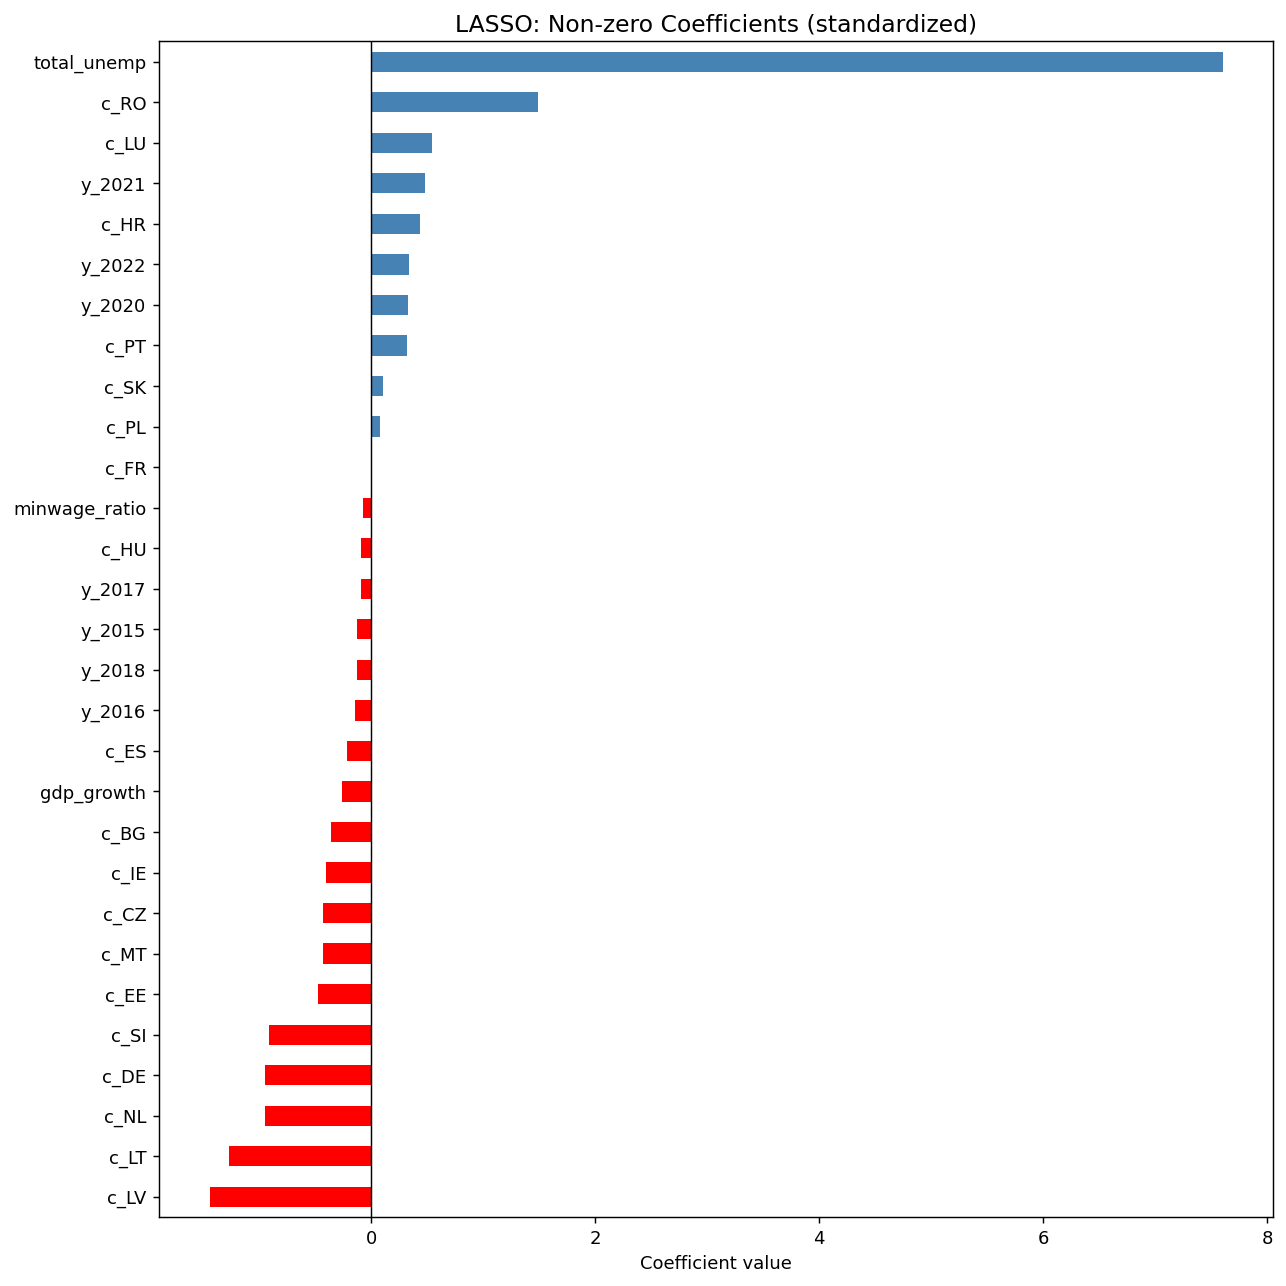

In [6]:
# ============================================
# MODEL 2: LASSO
# ============================================
X_lasso = pd.concat([
    df[['minwage_ratio','gdp_growth','total_unemp']],
    country_dummies,
    year_dummies
], axis=1).astype(float)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_lasso)

lasso_cv = LassoCV(cv=5, random_state=42, max_iter=10000)
lasso_cv.fit(X_scaled, df['youth_unemp'])

coef_series = pd.Series(lasso_cv.coef_, index=X_lasso.columns)
mw_coef = coef_series['minwage_ratio']
nonzero = (coef_series != 0).sum()

print('=== MODEL 2: LASSO ===')
print(f'Best alpha (lambda):         {lasso_cv.alpha_:.4f}')
print(f'Non-zero coefficients:       {nonzero} / {len(coef_series)}')
print(f'Coefficient (minwage_ratio): {mw_coef:.4f}')
print(f'\nTop 10 non-zero coefficients (by absolute value):')
print(coef_series[coef_series != 0].abs()
      .sort_values(ascending=False).head(10).round(4))

# Plot
fig, ax = plt.subplots(figsize=(10, 10))
top_coefs = coef_series[coef_series != 0].sort_values()
colors_lasso = ['red' if c < 0 else 'steelblue' for c in top_coefs]
top_coefs.plot(kind='barh', ax=ax, color=colors_lasso)
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_title('LASSO: Non-zero Coefficients (standardized)', fontsize=13)
ax.set_xlabel('Coefficient value')
plt.tight_layout()
plt.show()

### LASSO interpretation

The output reports the selected penalty and non-zero standardized coefficients. The minimum wage coefficient is measured per one standard deviation of that predictor. It should not be compared directly with the unstandardized OLS coefficient. No p-value or causal interpretation is assigned to this penalized coefficient.


In [7]:
# ============================================
# MODEL 3: DOUBLEML WITH COUNTRY/YEAR DUMMIES
# ============================================
country_d_dml = pd.get_dummies(df['country'], drop_first=True, prefix='c')
year_d_dml = pd.get_dummies(df['year'], drop_first=True, prefix='y')

X_dml = pd.concat([
    df[['gdp_growth', 'total_unemp']],
    country_d_dml,
    year_d_dml
], axis=1).astype(float)

df_dml = pd.concat([
    df[['youth_unemp', 'minwage_ratio']],
    X_dml
], axis=1)

dml_data = DoubleMLData(
    df_dml,
    y_col='youth_unemp',
    d_cols='minwage_ratio',
    x_cols=list(X_dml.columns)
)

ml_l = RandomForestRegressor(n_estimators=200, max_depth=3, random_state=42)
ml_m = RandomForestRegressor(n_estimators=200, max_depth=3, random_state=42)

np.random.seed(42)
dml_plr = DoubleMLPLR(dml_data, ml_l=ml_l, ml_m=ml_m, n_folds=5)
dml_plr.fit()

print('=== MODEL 3: DOUBLEML PLR ===')
print(dml_plr.summary)

=== MODEL 3: DOUBLEML PLR ===
                   coef   std err         t     P>|t|     2.5 %    97.5 %
minwage_ratio  0.115444  0.082589  1.397805  0.162172 -0.046428  0.277315


### DoubleML comparison

The DoubleML estimate and its interval are printed above. Compare its sign with the fixed-effects estimate, but do not interpret this exercise as establishing causality. Nuisance learners, sample splitting, sample size and dependence within countries can affect the result.

The baseline fixed-effects estimate is small and statistically insignificant. LASSO supplies a regularized coefficient, not a significance test. The DoubleML result is an exploratory comparison with different inference assumptions.


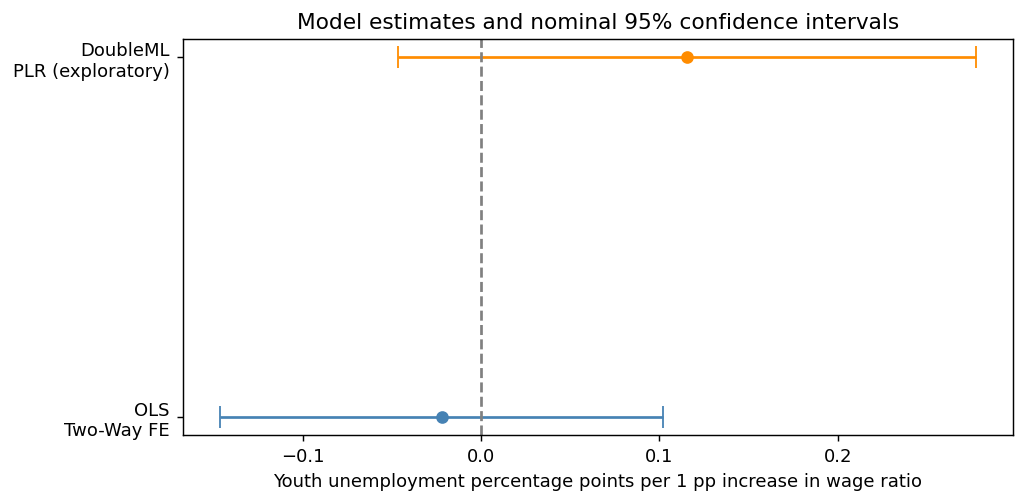

In [8]:
models = ['OLS\nTwo-Way FE', 'DoubleML\nPLR (exploratory)']
coefs = [ols_model.params['minwage_ratio'], float(dml_plr.coef[0])]
ols_ci = ols_model.conf_int().loc['minwage_ratio'].to_numpy()
dml_ci = dml_plr.confint().iloc[0].to_numpy()
fig, ax = plt.subplots(figsize=(8, 4))
for i, (coef, ci, color) in enumerate(zip(coefs, [ols_ci, dml_ci], ['steelblue', 'darkorange'])):
    ax.errorbar(coef, i, xerr=[[coef-ci[0]], [ci[1]-coef]], fmt='o', color=color, capsize=6)
ax.axvline(0, color='grey', linestyle='--')
ax.set_yticks(range(2), models)
ax.set_xlabel('Youth unemployment percentage points per 1 pp increase in wage ratio')
ax.set_title('Model estimates and nominal 95% confidence intervals')
plt.tight_layout()
plt.show()


### Coefficient plot

The figure compares baseline OLS and exploratory DoubleML estimates with nominal 95% confidence intervals. OLS uses country-clustered standard errors; DoubleML uses ordinary inference in this implementation. The intervals therefore have different dependence assumptions.

## 6. Sensitivity checks

The following checks change the time coverage, control set and timing of the minimum wage variable.


In [9]:
# ============================================
# ROBUSTNESS 1: PRE-COVID SAMPLE (2014-2019)
# ============================================
df_pre = df[df['year'] <= 2019].copy()

country_d = pd.get_dummies(df_pre['country'], drop_first=True, prefix='c')
year_d = pd.get_dummies(df_pre['year'], drop_first=True, prefix='y')

X_pre = pd.concat([
    df_pre[['minwage_ratio','gdp_growth','total_unemp']],
    country_d, year_d
], axis=1)

X_pre = sm.add_constant(X_pre)
ols_pre = sm.OLS(df_pre['youth_unemp'],
                 X_pre.astype(float)).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_pre['country']}
)

print('=== ROBUSTNESS 1: PRE-COVID SAMPLE (2014-2019) ===')
print(f'Observations:                {int(ols_pre.nobs)}')
print(f'Coefficient (minwage_ratio): {ols_pre.params["minwage_ratio"]:.4f}')
print(f'P-value:                     {ols_pre.pvalues["minwage_ratio"]:.4f}')
print(f'95% CI: [{ols_pre.conf_int().loc["minwage_ratio",0]:.4f}, '
      f'{ols_pre.conf_int().loc["minwage_ratio",1]:.4f}]')

=== ROBUSTNESS 1: PRE-COVID SAMPLE (2014-2019) ===
Observations:                119
Coefficient (minwage_ratio): -0.0695
P-value:                     0.4699
95% CI: [-0.2579, 0.1190]


In [10]:
# ============================================
# ROBUSTNESS 2: WITHOUT TOTAL UNEMPLOYMENT
# ============================================
X_no_unemp = pd.concat([
    df[['minwage_ratio','gdp_growth']],
    country_dummies, year_dummies
], axis=1)
X_no_unemp = sm.add_constant(X_no_unemp)

ols_no_unemp = sm.OLS(df['youth_unemp'],
    X_no_unemp.astype(float)).fit(
    cov_type='cluster',
    cov_kwds={'groups': df['country']})

print('=== ROBUSTNESS 2: WITHOUT TOTAL UNEMPLOYMENT ===')
print(f'Coefficient: {ols_no_unemp.params["minwage_ratio"]:.4f}')
print(f'P-value:     {ols_no_unemp.pvalues["minwage_ratio"]:.4f}')
print(f'\n=== COMPARISON ===')
print(f'With total_unemp:    -0.0221 (p=0.727)')
print(f'Without total_unemp: {ols_no_unemp.params["minwage_ratio"]:.4f} '
      f'(p={ols_no_unemp.pvalues["minwage_ratio"]:.3f})')

=== ROBUSTNESS 2: WITHOUT TOTAL UNEMPLOYMENT ===
Coefficient: -0.4583
P-value:     0.0000

=== COMPARISON ===
With total_unemp:    -0.0221 (p=0.727)
Without total_unemp: -0.4583 (p=0.000)


In [11]:
# ============================================
# ROBUSTNESS 3: LAGGED TREATMENT
# ============================================
df_lag = df.sort_values(['country','year']).copy()
df_lag['minwage_lag'] = df_lag.groupby('country')['minwage_ratio'].shift(1)
df_lag = df_lag.dropna(subset=['minwage_lag'])

country_d_lag = pd.get_dummies(df_lag['country'], drop_first=True, prefix='c')
year_d_lag = pd.get_dummies(df_lag['year'], drop_first=True, prefix='y')

X_lag = pd.concat([
    df_lag[['minwage_lag','gdp_growth','total_unemp']],
    country_d_lag, year_d_lag
], axis=1)
X_lag = sm.add_constant(X_lag)

ols_lag = sm.OLS(df_lag['youth_unemp'],
    X_lag.astype(float)).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_lag['country']})

print('=== ROBUSTNESS 3: LAGGED TREATMENT ===')
print(f'Observations:              {int(ols_lag.nobs)}')
print(f'Coefficient (minwage_lag): {ols_lag.params["minwage_lag"]:.4f}')
print(f'P-value:                   {ols_lag.pvalues["minwage_lag"]:.4f}')

=== ROBUSTNESS 3: LAGGED TREATMENT ===
Observations:              157
Coefficient (minwage_lag): -0.0031
P-value:                   0.9489


### Interpretation of sensitivity checks

The pre-COVID and lagged specifications give small, statistically insignificant estimates. Excluding overall unemployment yields a larger negative, statistically significant estimate. The conclusion is therefore sensitive to the control set.

This does not establish that overall unemployment is the true causal driver or that including it is necessarily appropriate: it could also be affected by minimum wage policy and overlaps conceptually with the youth outcome. The alternative specifications may answer different conditional questions.

## 7. Limitations

- Fixed effects absorb stable country differences and common year shocks; they do not rule out reverse causality or time-varying confounding.
- The short panel, 20 country clusters and limited controls constrain inference.
- LASSO uses ordinary cross-validation and penalizes the dummy coefficients as well as the other predictors; it is a regularization illustration rather than a validated forecasting model.
- DoubleML uses ordinary cross-fitting/inference, not a cluster-aware panel design. See the [official cluster-robust DoubleML example](https://docs.doubleml.org/stable/examples/py_double_ml_multiway_cluster.html).
- A confidence interval containing zero does not demonstrate the absence of an effect.
- The supplied processed CSV is reproducible input, but the original Eurostat downloads and merge script are not included. Source descriptions are inherited from the course notebook and have not been independently audited against raw extracts.


## 8. Conclusion

The baseline two-way fixed-effects estimate is close to zero and statistically insignificant. The negative association is substantially larger when overall unemployment is excluded. The main lesson is specification sensitivity, rather than a definitive finding that minimum wages do or do not affect youth unemployment.

This project demonstrates panel-data analysis, comparison of econometric and machine-learning approaches, and critical interpretation of model assumptions.

## References and data attribution

- Source: Eurostat. Dataset codes reported in the course notebook: `une_rt_a`, `earn_mw_avgr2`, `tec00115`.
- [Eurostat data reuse policy](https://ec.europa.eu/eurostat/help/copyright-notice).
- [DoubleML cluster-robust example](https://docs.doubleml.org/stable/examples/py_double_ml_multiway_cluster.html).
- Neumark & Wascher (2004), *ILR Review*, 57(2), 223–248.
- Dube, Lester & Reich (2010), *Review of Economics and Statistics*, 92(4), 945–964.
- Chernozhukov et al. (2018), *The Econometrics Journal*, 21(1), C1–C68.
